# Random Forest — Strategy B

**Why RF after LogReg?** Different inductive bias. RF captures non-linear feature interactions LogReg can't, handles mixed feature scales without standardization sensitivity, and natively handles class imbalance through tree splits (each split locally optimizes information gain, no global re-weighting needed).

**What this notebook shows:**
1. Two RF configs side by side:
   - **Config 1**: vanilla RF, threshold 0.5
   - **Config 2**: RF + per-class threshold tuning on val
2. Why no `class_weight` config: RF + `class_weight='balanced'` typically hurts on multi-label (over-corrects positives, common classes drop hard). For trees, threshold tuning alone is usually sufficient.
3. Comparison reference points: random ≈ 0.05 macro F1 (floor), LogReg Config 3 = 0.47 macro F1.

**Hyperparameters** are mid-range defaults — `n_estimators=200`, `max_depth=None`, `n_jobs=-1`. Not tuned, intentionally. This is a baseline RF, not a hyperparameter search.

**Compute warning:** RF on 100k × 960 with 200 trees takes ~5-15 minutes on CPU. Strategy B is ~14% larger so add a couple of minutes there.

In [1]:
# ============================================================================
# CELL 1 — Setup
# ============================================================================
import sys
from pathlib import Path

_SHARED = Path.cwd().resolve().parents[1] / '_shared'
if str(_SHARED) not in sys.path:
    sys.path.insert(0, str(_SHARED))

import json
import time
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier

from data import load_splits, find_root, load_config
from eval import (
    predict_with_threshold, tune_thresholds_on_val,
    classification_report,
)
from plot import plot_per_class_f1, plot_confusion_matrices

warnings.filterwarnings('ignore', category=UserWarning)

# --- Config ---------------------------------------------------------------
STRATEGY    = 'B'
MODEL_NAME  = 'rf'
NOTEBOOK_ID = '04'
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Mid-range RF defaults — not tuned
N_ESTIMATORS = 200
MAX_DEPTH    = None       # unlimited
MIN_LEAF     = 2
N_JOBS       = -1

# --- Paths ---------------------------------------------------------------
ROOT       = find_root()
CONFIG     = load_config()
ARTIFACTS  = ROOT / CONFIG['paths'][f'strategy_{STRATEGY.lower()}_artifacts']
RESULTS_DIR = ARTIFACTS / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Strategy:      {STRATEGY}")
print(f"Model:         {MODEL_NAME}")
print(f"Hyperparams:   n_estimators={N_ESTIMATORS}, max_depth={MAX_DEPTH}, min_leaf={MIN_LEAF}")
print(f"Results dir:   {RESULTS_DIR}")

Strategy:      B
Model:         rf
Hyperparams:   n_estimators=200, max_depth=None, min_leaf=2
Results dir:   /Users/amrabdullah/AI_2026ss/mlpc/strategy_B_with_aug/artifacts/results


## Cell 2 — Load splits

For Strategy B you should see the `train composition: X real + Y aug` line — that's the augmentation in action.

In [2]:
# ============================================================================
# CELL 2 — Load data
# ============================================================================
d = load_splits(STRATEGY)
print(d.summary())

class_names = list(d.class_names)

Strategy B
  X_train: (114526, 960)  Y_train: (114526, 15)
  X_val:   (34245, 960)  Y_val:   (34245, 15)
  X_test:  (33828, 960)  Y_test:  (33828, 15)
  D = 960 features, C = 15 classes
  train composition: 100,166 real + 14,360 aug = 114,526 (+14.3% of real)


## Cell 3 — Train Config 1 (vanilla RF)

`RandomForestClassifier` is natively multi-output — no `OneVsRestClassifier` wrapper needed. It fits 200 trees on the full multi-label target matrix and at predict time aggregates leaf-level positive class probabilities.

**Why no `class_weight`**: for multi-label RF on 24× imbalanced data, `class_weight='balanced_subsample'` tends to over-correct — trees pick splits that favor rare-class purity at the cost of common-class accuracy. Empirically, threshold tuning on val (Config 2) gives the same or better result with no training-time cost.

**Expected duration** on 100k × 960 with 200 trees and `n_jobs=-1`: ~5-15 min depending on cores.

In [3]:
# ============================================================================
# CELL 3 — Train Config 1 (vanilla RF)
# ============================================================================
t0 = time.time()
model_1 = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    min_samples_leaf=MIN_LEAF,
    n_jobs=N_JOBS,
    random_state=RANDOM_SEED,
    verbose=1,
)
model_1.fit(d.X_train, d.Y_train)
elapsed_1 = time.time() - t0
print(f"\nConfig 1 (vanilla RF) trained in {elapsed_1/60:.1f} min")

# Probabilities on val
# For multi-label RF, predict_proba returns a list of (N, 2) arrays.
# We want P(class=1) for each class → stack column 1 from each.
val_probs_raw = model_1.predict_proba(d.X_val)
val_probs_1 = np.column_stack([p[:, 1] for p in val_probs_raw])
print(f"Val probs shape: {val_probs_1.shape}")

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 180 tasks      | elapsed:  6.0min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  6.8min finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.



Config 1 (vanilla RF) trained in 6.8 min


[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.3s


Val probs shape: (34245, 15)


[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    1.9s
[Parallel(n_jobs=10)]: Done 200 out of 200 | elapsed:    2.1s finished


## Cell 4 — Evaluate Config 1 and 2 on val

- **Config 1** uses threshold 0.5 (vanilla).
- **Config 2** reuses the same model with per-class thresholds tuned on val. No retraining — RF probabilities are fixed, only the decision rule changes.

Since we're not retraining, evaluation is fast (seconds).

In [4]:
# ============================================================================
# CELL 4 — Evaluate on val (Config 1 + Config 2)
# ============================================================================
# Config 1 — vanilla, threshold 0.5
Y_val_pred_1 = predict_with_threshold(val_probs_1, 0.5)
report_val_1 = classification_report(d.Y_val, Y_val_pred_1, class_names)

# Config 2 — per-class thresholds tuned on val
threshold_df = tune_thresholds_on_val(val_probs_1, d.Y_val, class_names=class_names)
thresholds_2 = threshold_df['threshold'].loc[class_names].values
Y_val_pred_2 = predict_with_threshold(val_probs_1, thresholds_2)
report_val_2 = classification_report(d.Y_val, Y_val_pred_2, class_names)

print("=== VAL RESULTS ===\n")
print(f"  {'config':<35s}  {'macro_f1':>9s}  {'micro_f1':>9s}")
for name, rep in [
    ("1 - vanilla RF (th=0.5)", report_val_1),
    ("2 - vanilla RF + tuned thresholds", report_val_2),
]:
    m = rep.loc['macro avg', 'f1']
    u = rep.loc['micro avg', 'f1']
    print(f"  {name:<35s}  {m:>9.4f}  {u:>9.4f}")

print(f"\n=== Tuned thresholds (Config 2) ===")
print(threshold_df[['threshold', 'val_f1', 'val_support']].to_string())

=== VAL RESULTS ===

  config                                macro_f1   micro_f1
  1 - vanilla RF (th=0.5)                 0.2922     0.4210
  2 - vanilla RF + tuned thresholds       0.5008     0.5803

=== Tuned thresholds (Config 2) ===
                            threshold  val_f1  val_support
class                                                     
bell_ringing                     0.15  0.4327          480
coffee_machine                   0.26  0.5661         1073
cutlery_dishes                   0.23  0.5502         1828
door_open_close                  0.18  0.3201         1177
footsteps                        0.24  0.4769         4033
keyboard_typing                  0.24  0.6937         3107
keychain                         0.26  0.5976         1553
light_switch                     0.05  0.1924          140
microwave                        0.21  0.6000         2253
phone_ringing                    0.19  0.5976         2122
running_water                    0.32  0.7570         

## Cell 5 — Per-class comparison

Same logic as logreg: tuning thresholds usually helps rare classes most. Vanilla RF with threshold 0.5 misses most rare-class positives because their tree-leaf probabilities never reach 0.5.

In [5]:
# ============================================================================
# CELL 5 — Per-class F1 comparison
# ============================================================================
comparison = pd.DataFrame({
    'config_1_vanilla':     report_val_1.loc[class_names, 'f1'],
    'config_2_tuned':       report_val_2.loc[class_names, 'f1'],
    'support':              report_val_1.loc[class_names, 'support'],
})
comparison['gain_tuned'] = (comparison['config_2_tuned'] - comparison['config_1_vanilla']).round(4)
comparison = comparison.sort_values('support', ascending=True)

print("=== Per-class F1 by config (sorted rare → common) ===\n")
print(comparison.to_string())

=== Per-class F1 by config (sorted rare → common) ===

                            config_1_vanilla  config_2_tuned  support  gain_tuned
class                                                                            
light_switch                          0.0000          0.1924    140.0      0.1924
window_open_close                     0.0000          0.2420    421.0      0.2420
bell_ringing                          0.1726          0.4327    480.0      0.2601
wardrobe_drawer_open_close            0.0000          0.2327    613.0      0.2327
toilet_flushing                       0.4138          0.5806    967.0      0.1668
coffee_machine                        0.4018          0.5661   1073.0      0.1643
door_open_close                       0.0101          0.3201   1177.0      0.3100
keychain                              0.4454          0.5976   1553.0      0.1522
cutlery_dishes                        0.2361          0.5502   1828.0      0.3141
phone_ringing                         0.376

## Cell 6 — Pick val winner, run test once

Same discipline: macro F1 on val picks the winner; test runs once on that one config.

In [6]:
# ============================================================================
# CELL 6 — Pick winner on val, evaluate on test
# ============================================================================
val_scores = {
    1: report_val_1.loc['macro avg', 'f1'],
    2: report_val_2.loc['macro avg', 'f1'],
}
winner = max(val_scores, key=val_scores.get)
print(f"Winner on val: Config {winner} (macro F1 = {val_scores[winner]:.4f})\n")

if winner == 1:
    winning_thresholds = np.full(d.C, 0.5)
else:
    winning_thresholds = thresholds_2

# Test probs from the SAME model_1 — Config 2 only changes the threshold
test_probs_raw = model_1.predict_proba(d.X_test)
test_probs = np.column_stack([p[:, 1] for p in test_probs_raw])
Y_test_pred = predict_with_threshold(test_probs, winning_thresholds)
report_test = classification_report(d.Y_test, Y_test_pred, class_names)

print(f"=== TEST RESULTS (Config {winner}) ===")
print(report_test.round(4).to_string())

Winner on val: Config 2 (macro F1 = 0.5008)



[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.3s


=== TEST RESULTS (Config 2) ===
                            precision  recall      f1  support
class                                                         
bell_ringing                   0.4736  0.5197  0.4956    483.0
coffee_machine                 0.6458  0.4587  0.5364   1236.0
cutlery_dishes                 0.5528  0.5736  0.5630   2045.0
door_open_close                0.3397  0.3491  0.3443   1077.0
footsteps                      0.4923  0.5082  0.5001   4256.0
keyboard_typing                0.7279  0.5794  0.6452   3333.0
keychain                       0.6187  0.5020  0.5543   1474.0
light_switch                   0.0717  0.2386  0.1102     88.0
microwave                      0.6251  0.6964  0.6588   2579.0
phone_ringing                  0.5815  0.6185  0.5994   2076.0
running_water                  0.7140  0.8012  0.7551   4190.0
toilet_flushing                0.7278  0.4870  0.5835   1076.0
vacuum_cleaner                 0.5732  0.7786  0.6603   1992.0
wardrobe_drawer_open_cl

[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    1.4s
[Parallel(n_jobs=10)]: Done 200 out of 200 | elapsed:    1.6s finished


## Cell 7 — Plots

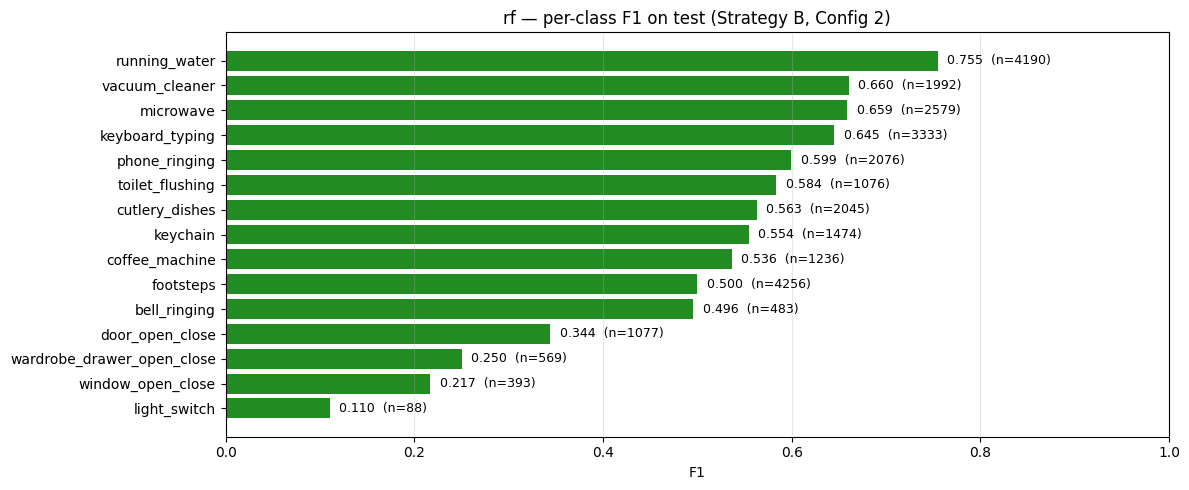

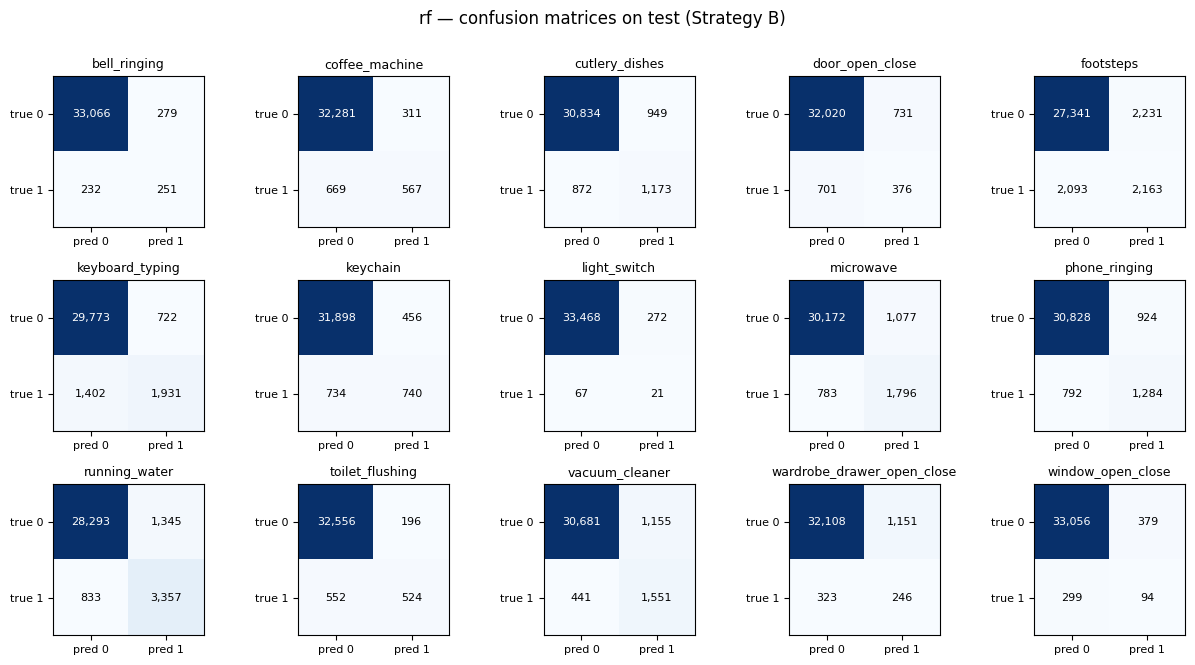

/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packag

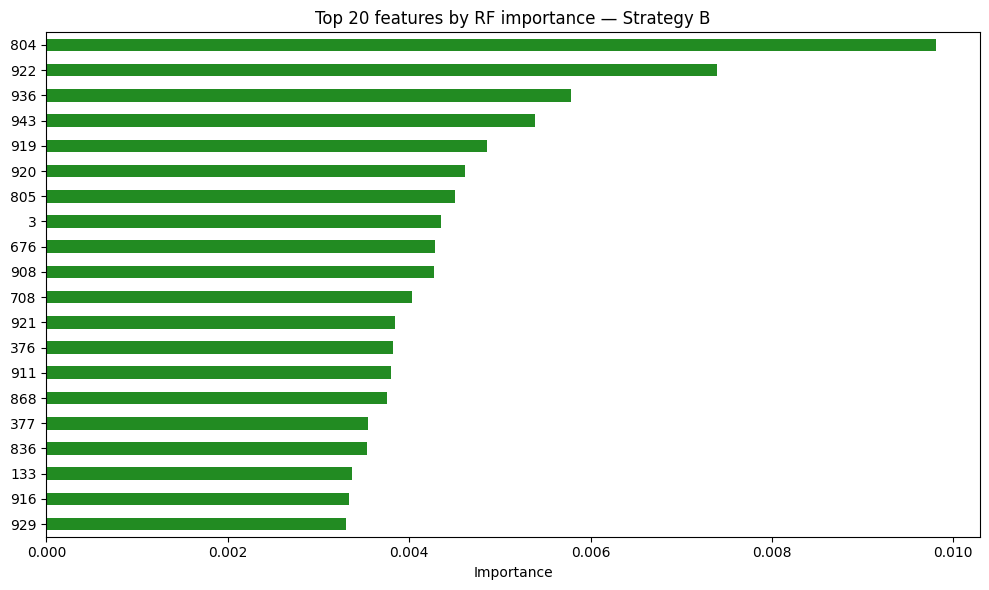

In [7]:
# ============================================================================
# CELL 7 — Plots
# ============================================================================
fig, ax = plot_per_class_f1(
    report_test, class_names=class_names,
    title=f"{MODEL_NAME} — per-class F1 on test (Strategy {STRATEGY}, Config {winner})",
    color='forestgreen',
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_per_class_f1.png",
            dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plot_confusion_matrices(
    d.Y_test, Y_test_pred, class_names=class_names,
    title=f"{MODEL_NAME} — confusion matrices on test (Strategy {STRATEGY})",
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_confusion.png",
            dpi=150, bbox_inches='tight')
plt.show()

# --- Feature importances (RF gives us this for free) ---
fi = pd.Series(model_1.feature_importances_, index=d.feature_names if len(d.feature_names) == d.D else range(d.D))
fi = fi.sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(10, 6))
fi.iloc[::-1].plot.barh(ax=ax, color='forestgreen')
ax.set_xlabel('Importance')
ax.set_title(f'Top 20 features by RF importance — Strategy {STRATEGY}')
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_top_features.png",
            dpi=150, bbox_inches='tight')
plt.show()

## Cell 8 — Save results JSON

In [8]:
# ============================================================================
# CELL 8 — Save results
# ============================================================================
def df_to_jsonable(df):
    return {idx: {col: (int(v) if col == 'support' else float(v))
                  for col, v in row.items()}
            for idx, row in df.iterrows()}

results = {
    'meta': {
        'strategy':         STRATEGY,
        'model':            MODEL_NAME,
        'notebook_id':      NOTEBOOK_ID,
        'timestamp':        datetime.now().isoformat(timespec='seconds'),
        'random_seed':      RANDOM_SEED,
        'training_seconds': {'config_1_vanilla': round(elapsed_1, 2)},
        'n_train':          int(d.N_train),
        'n_val':            int(d.N_val),
        'n_test':           int(d.N_test),
    },
    'winning_config': {
        'config_id':       int(winner),
        'description':     [
            "1 - vanilla RF (threshold 0.5)",
            "2 - vanilla RF + per-class thresholds tuned on val",
        ][winner - 1],
        'thresholds':      [float(t) for t in winning_thresholds],
        'hyperparameters': {
            'n_estimators':     N_ESTIMATORS,
            'max_depth':        str(MAX_DEPTH),
            'min_samples_leaf': MIN_LEAF,
            'class_weight':     None,
        },
    },
    'val_scores_macro_f1': {f'config_{k}': float(v) for k, v in val_scores.items()},
    'val_report':  df_to_jsonable(report_val_2 if winner == 2 else report_val_1),
    'test_report': df_to_jsonable(report_test),
    'headline_test': {
        'macro_f1':    float(report_test.loc['macro avg', 'f1']),
        'micro_f1':    float(report_test.loc['micro avg', 'f1']),
        'weighted_f1': float(report_test.loc['weighted avg', 'f1']),
    },
}

out_path = RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}.json"
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Saved: {out_path}")
print(f"\n=== HEADLINE ===")
print(f"  Strategy {STRATEGY} / {MODEL_NAME} / Config {winner}")
print(f"  Test macro F1:    {results['headline_test']['macro_f1']:.4f}")
print(f"  Test micro F1:    {results['headline_test']['micro_f1']:.4f}")
print(f"  Test weighted F1: {results['headline_test']['weighted_f1']:.4f}")
print(f"\nReference points:")
print(f"  Random (stratified):  ~0.05 macro F1  (floor)")
print(f"  LogReg Config 3 A:     0.4723 macro F1")
print(f"  LogReg Config 3 B:     0.4749 macro F1")

Saved: /Users/amrabdullah/AI_2026ss/mlpc/strategy_B_with_aug/artifacts/results/04_rf.json

=== HEADLINE ===
  Strategy B / rf / Config 2
  Test macro F1:    0.4982
  Test micro F1:    0.5832
  Test weighted F1: 0.5884

Reference points:
  Random (stratified):  ~0.05 macro F1  (floor)
  LogReg Config 3 A:     0.4723 macro F1
  LogReg Config 3 B:     0.4749 macro F1
